In [1]:
import pandas as pd
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *

sys.path.append("../..")
from analyses_plot_utils import *

In [2]:
sqy2h_outputs_dir = "../3_outputs/sqY2H"
metadata_outputs_dir = "../../../1_allele_collection/3_outputs"
integrative_inputs = "../../../3_integrated_assay_results/1_inputs"

In [3]:
# process metadata
metadata = pl.DataFrame(pd.read_csv(f"{metadata_outputs_dir}/varchamp_seq_confirm_alleles_clinvar_gnomad.tsv", sep="\t"))
mut_cols = ["mutation_id_rc4", "mutation_id_cegs2", "mutation_id_edgotyping3"]
id_vars = [col for col in metadata.columns if col not in mut_cols]
# metadata = metadata.unpivot(index=id_vars, 
#                             on=mut_cols,
#                             variable_name="mutation_collection",
#                             value_name="mut_id")

priority_col = ["orf_id", "mut_id", "symbol", "aa_change", "ensembl_gene_id", "clinvar_clnsig_clean", "gnomad_af", "StarStatus"]
metadata = metadata.select(priority_col).filter(~pl.col("mut_id").is_null()).with_columns(
    pl.col("mut_id").cast(pl.Int64).alias("mut_id"),
    pl.col("orf_id").cast(pl.Int64).alias("orf_id")
)

In [4]:
# merge scores with metadata
scores = pl.read_csv(f"{sqy2h_outputs_dir}/5_variant_perturbation_scores_automated_summed.csv").with_columns(
    pl.col("db_orf_id").cast(pl.Int64).alias("orf_id"),
    pl.col("db_mut_id").cast(pl.Int64).alias("mut_id"),
).drop(["db_orf_id", "db_mut_id"])

scores = scores.join(metadata, on=["orf_id", "mut_id"])
# scores.write_csv(f"{sqy2h_outputs_dir}/6_variant_perturbation_scores_annotated.csv")
# scores.write_csv(f"{integrative_inputs}/ppi_scores.csv")
# scores = scores.filter(pl.col("clinvar_clnsig_clean") != "5_Others")

In [5]:
scores_pd = scores.to_pandas()
scores_pd.clinvar_clnsig_clean.value_counts()

clinvar_clnsig_clean
1_Pathogenic     239
4_VUS             91
3_Conflicting     75
5_Others          42
2_Benign          30
Name: count, dtype: int64

In [6]:
scores_pd[scores_pd.symbol == 'MVK']

,euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,num_edges,...,StarStatus,allele_0,orf_id,mut_id,symbol_right,aa_change_right,ensembl_gene_id_right,clinvar_clnsig_clean_right,gnomad_af_right,StarStatus_right
3,1493.637960,1493.637960,0.638591,1493.637960,2.766949,2.766949,1.468296,1.468296,NaN,1,...,2.0,MVK_His20Pro,281,3,MVK,His20Pro,ENSG00000110921,1_Pathogenic,0.000010,2.0
4,724.060184,-724.060184,-0.309565,724.060184,0.763612,0.763612,-0.389088,0.389088,NaN,1,...,2.0,MVK_Ser52Asn,281,5,MVK,Ser52Asn,ENSG00000110921,2_Benign,0.110614,2.0
5,1322.814447,-1322.814447,-0.565557,1322.814447,0.638750,0.638750,-0.646676,0.646676,NaN,1,...,1.0,MVK_Cys101Tyr,281,7,MVK,Cys101Tyr,ENSG00000110921,4_VUS,NaN,1.0
6,1052.831419,1052.831419,0.450128,1052.831419,1.818606,1.818606,0.862833,0.862833,NaN,1,...,2.0,MVK_Ala148Thr,281,11,MVK,Ala148Thr,ENSG00000110921,1_Pathogenic,0.000005,2.0
7,988.607886,988.607886,0.422670,988.607886,1.732112,1.732112,0.792532,0.792532,NaN,1,...,2.0,MVK_Pro167Leu,281,13,MVK,Pro167Leu,ENSG00000110921,1_Pathogenic,0.000009,2.0
8,783.078416,-783.078416,-0.334798,783.078416,0.749177,0.749177,-0.416621,0.416621,NaN,1,...,NaN,MVK_Leu255Pro,281,18,MVK,Leu255Pro,ENSG00000110921,1_Pathogenic,NaN,NaN
9,504.124218,504.124218,0.215534,504.124218,1.274752,1.274752,0.350217,0.350217,NaN,1,...,1.0,MVK_Ile268Val,281,19,MVK,Ile268Val,ENSG00000110921,3_Conflicting,0.000005,1.0
10,185.788237,-185.788237,-0.079432,185.788237,0.926413,0.926413,-0.110272,0.110272,NaN,1,...,2.0,MVK_Val278Met,281,21,MVK,Val278Met,ENSG00000110921,4_VUS,0.000026,2.0
11,1161.196129,1161.196129,0.496459,1161.196129,1.985934,1.985934,0.989818,0.989818,NaN,1,...,NaN,MVK_Asn301Thr,281,23,MVK,Asn301Thr,ENSG00000110921,1_Pathogenic,0.000004,NaN
12,853.126826,853.126826,0.364746,853.126826,1.574175,1.574175,0.654596,0.654596,NaN,1,...,2.0,MVK_Asn205Asp,281,744,MVK,Asn205Asp,ENSG00000110921,1_Pathogenic,0.000027,2.0


In [7]:
# Drop duplicates on allele_0, keeping the one with higher mut_id value
scores_dedup = scores.sort("mut_id", descending=True).unique(subset=["allele_0"], keep="first")

scores_dedup.filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic", "2_Benign"])
).with_columns(
    pl.when(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")
    .then(pl.lit("Positive"))
    .otherwise(pl.lit("Negative"))
    .alias("referenceSet"),
    pl.col("normalized_euclid_distance_normalized").alias("score"),
    pl.col("allele_0").alias("hgvsp")
).select(
    pl.col(["hgvsp", "score", "referenceSet", "normalized_euclid_distance_normalized", "allele_0", "clinvar_clnsig_clean"])
).write_csv("../3_outputs/sqY2H/PPI_referenceSet.csv")

scores_dedup.with_columns(
    pl.col("normalized_euclid_distance_normalized").alias("score"),
    pl.col("allele_0").alias("hgvs_pro")
).select(pl.col(["hgvs_pro", "score"])).write_csv("../3_outputs/sqY2H/PPI_allScores.csv")

In [8]:
scores_dedup

euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,normalized_euclid_distance,normalized_mahalanobis_distance,normalized_euclid_distance_normalized,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,orf_id,mut_id,symbol_right,aa_change_right,ensembl_gene_id_right,clinvar_clnsig_clean_right,gnomad_af_right,StarStatus_right
f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,str,f64,f64,str,i64,i64,str,str,str,str,f64,f64
6195.762408,6195.762408,0.740643,6195.762408,3.855687,3.855687,1.946988,1.946988,null,1,false,0.0,-6195.762408,-0.740643,null,2169.622247,0.259357,6195.762408,null,0.650942,"""PCCA""","""Met348Lys""","""1043T>A""","""ENSG00000175198""","""CEGS2""","""1_Pathogenic""",0.000003,2.0,"""PCCA_Met348Lys""",888,200363,"""PCCA""","""Met348Lys""","""ENSG00000175198""","""1_Pathogenic""",0.000003,2.0
5473.890499,5244.647308,0.748596,5244.647308,3.977664,3.977664,1.991921,1.991921,13.252449,4,false,0.0,-1415.580128,-0.251756,0.39299,1669.101986,0.251404,2736.94525,6.626225,0.28755,"""PRKAR1A""","""Arg335Pro""","""1004G>C""","""ENSG00000108946""","""CEGS2""","""1_Pathogenic""",null,null,"""PRKAR1A_Arg335Pro""",2455,200621,"""PRKAR1A""","""Arg335Pro""","""ENSG00000108946""","""1_Pathogenic""",null,null
1011.123445,-1011.123445,-0.152665,1011.123445,0.867555,0.867555,-0.204974,0.204974,null,1,false,0.0,1011.123445,0.152665,null,7634.263447,1.152665,1011.123445,null,0.106231,"""KCTD1""","""Gly62Asp""","""185G>A""","""ENSG00000134504""","""CEGS2""","""1_Pathogenic""",null,1.0,"""KCTD1_Gly62Asp""",14221,218283,"""KCTD1""","""Gly62Asp""","""ENSG00000134504""","""1_Pathogenic""",null,1.0
2742.168683,2742.168683,0.77832,2742.168683,4.511011,4.511011,2.173451,2.173451,null,1,false,0.0,-2742.168683,-0.77832,null,781.019624,0.22168,2742.168683,null,0.288099,"""AIPL1""","""Met79Thr""","""236T>C""","""ENSG00000129221""","""RC4""","""5_Others""",null,null,"""AIPL1_Met79Thr""",7167,12744,"""AIPL1""","""Met79Thr""","""ENSG00000129221""","""5_Others""",6.8407e-7,null
9028.451439,2760.240645,0.39926,2760.240645,1.664614,1.664614,0.735188,0.735188,null,15,false,0.0,834.023534,0.810715,2.802569,2523.666722,0.60074,2331.136138,null,0.244915,"""LITAF""","""Thr49Met""","""146C>T""","""ENSG00000189067""","""RC4""","""3_Conflicting""",null,1.0,"""LITAF_Thr49Met""",52920,2685,"""LITAF""","""Thr49Met""","""ENSG00000189067""","""3_Conflicting""",0.001281,1.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
5254.555658,4111.530892,0.833944,4111.530892,6.022076,6.022076,2.590261,2.590261,null,2,false,0.5,-3691.74137,-0.664619,0.239462,818.691519,0.166056,3715.531938,null,0.390363,"""KCNJ2""","""Val295Ala""","""884T>C""","""ENSG00000123700""","""Edgotyping3""","""4_VUS""",null,2.0,"""KCNJ2_Val295Ala""",100016069,2639,"""KCNJ2""","""Val295Ala""","""ENSG00000123700""","""4_VUS""",null,2.0
8313.960384,3848.001428,0.771227,3848.001428,4.371149,4.371149,2.128013,2.128013,null,15,false,0.0,-620.828675,0.352359,1.897952,1141.451004,0.228773,2146.655341,null,0.225533,"""LITAF""","""Pro135Thr""","""403C>A""","""ENSG00000189067""","""Edgotyping3""","""1_Pathogenic""",null,1.0,"""LITAF_Pro135Thr""",52920,2669,"""LITAF""","""Pro135Thr""","""ENSG00000189067""","""1_Pathogenic""",null,1.0
5159.908705,-5159.908705,-1.587944,5159.908705,0.386407,0.386407,-1.371806,1.371806,null,1,false,0.0,5159.908705,1.587944,null,8409.336233,2.587944,5159.908705,null,0.542112,"""VHL""","""Ser65Trp""","""194C>G""","""ENSG00000134086""","""RC4""","""1_Pathogenic""",6.8942e-7,3.0,"""VHL_Ser65Trp""",13320,203989,"""VHL""","""Ser65Trp""","""ENSG0000

In [9]:
%%bash
source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh
conda activate py310

Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_bcv.log" --bandwidth "bcv" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_default.log" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_nrd.log" --bandwidth "nrd" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_sj" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_sj.log" --printTransitions --bandwidth "SJ"

Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-07-30_11:20:20 INFO: Reading input 
2025-07-30_11:20:20 INFO: Calculating densties 
2025-07-30_11:20:20 INFO: Calculating densties 


Error in value[[3L]](cond) : 
  Normalization error: The function will not integrate.Two common causes are: 1.) The kernel is non-smooth, try a smooth kernel if possible. 2.) The supplied support is incorrect.
Calls: buildLLR.kernel ... tryCatch -> tryCatchList -> tryCatchOne -> <Anonymous>
In addition: Warning message:
In stats::bw.bcv(data) : minimum occurred at one end of the range
  Normalization error: The function will not integrate.Two common causes are: 1.) The kernel is non-smooth, try a smooth kernel if possible. 2.) The supplied support is incorrect.
Calls: buildLLR.kernel ... tryCatch -> tryCatchList -> tryCatchOne -> <Anonymous>
In addition: Warning message:
In stats::bw.bcv(data) : minimum occurred at one end of the range


2025-07-30_11:20:21 FATAL: Error in value[[3L]](cond) : 
  Normalization error: The function will not integrate.Two common causes are: 1.) The kernel is non-smooth, try a smooth kernel if possible. 2.) The supplied support is incorrect.
Calls: buildLLR.kernel ... tryCatch -> tryCatchList -> tryCatchOne -> <Anonymous>
 
  
  Normalization error: The function will not integrate.Two common causes are: 1.) The kernel is non-smooth, try a smooth kernel if possible. 2.) The supplied support is incorrect.
Calls: buildLLR.kernel ... tryCatch -> tryCatchList -> tryCatchOne -> <Anonymous>
 
  


Loading required package: parallel
Loading required package: maveLLR
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 
Warning message:
NAs introduced by coercion 


...

2025-07-30_11:20:25 FATAL: Error in value[[3L]](cond) : 
  Normalization error: The function will not integrate.Two common causes are: 1.) The kernel is non-smooth, try a smooth kernel if possible. 2.) The supplied support is incorrect.
Calls: buildLLR.kernel ... tryCatch -> tryCatchList -> tryCatchOne -> <Anonymous>
 
  
  Normalization error: The function will not integrate.Two common causes are: 1.) The kernel is non-smooth, try a smooth kernel if possible. 2.) The supplied support is incorrect.
Calls: buildLLR.kernel ... tryCatch -> tryCatchList -> tryCatchOne -> <Anonymous>
 
  


Loading required package: parallel
Loading required package: maveLLR
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 
Warning message:
NAs introduced by coercion 


2025-07-30_11:20:26 INFO: Reading input 
2025-07-30_11:20:26 INFO: Calculating densties 
2025-07-30_11:20:26 INFO: Calculating densties 
2025-07-30_11:20:27 INFO: Drawing LLR plot 
2025-07-30_11:20:27 INFO: Drawing LLR plot 
2025-07-30_11:20:27 INFO: Drawing PRC curve 
2025-07-30_11:20:27 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-07-30_11:20:27 INFO: Category transitions:  
  |======================================================================| 100%2025-07-30_11:20:27 INFO: Category transitions:  
0.526 : none -> patho.support
0.565 : patho.support -> patho.moderate
0.596 : patho.moderate -> patho.strong
0.607 : patho.strong -> patho.vstrong
2025-07-30_11:20:27 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-07-30_11:20:27 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd.csv 
0.526 : none -> patho.support
0.565 : patho.support -> patho.moderate
0.596 : patho.moderate -> 

Loading required package: parallel
Loading required package: maveLLR
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 
Warning message:
NAs introduced by coercion 


2025-07-30_11:20:28 INFO: Reading input 
2025-07-30_11:20:28 INFO: Calculating densties 
2025-07-30_11:20:28 INFO: Calculating densties 
2025-07-30_11:20:29 INFO: Drawing LLR plot 
2025-07-30_11:20:29 INFO: Drawing LLR plot 
2025-07-30_11:20:29 INFO: Drawing PRC curve 
2025-07-30_11:20:29 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-07-30_11:20:30 INFO: Category transitions:  
  |======================================================================| 100%2025-07-30_11:20:30 INFO: Category transitions:  
0.513 : none -> patho.support
0.547 : patho.support -> patho.moderate
0.579 : patho.moderate -> patho.strong
0.588 : patho.strong -> patho.vstrong
2025-07-30_11:20:30 INFO: Bootstrapping confidence intervals at  10000  iterations 
0.513 : none -> patho.support
0.547 : patho.support -> patho.moderate
0.579 : patho.moderate -> patho.strong
0.588 : patho.strong -> patho.vstrong
2025-07-30_11:20:30 INFO: Bootstrapping confidenc

In [10]:
# %%bash
# # source ~/software/anaconda3/etc/profile.d/conda.sh
# conda activate py310

# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_bcv.log" --bandwidth "bcv" --printTransitions --outlierSuppression 0.2
# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions --outlierSuppression 0.1


# ## Non-smooth, failed bandwidth:
# ## No need to run any more
# # Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_default.log" --printTransitions
# # Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_nrd.log" --bandwidth "nrd" --printTransitions
# # Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_sj" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_sj.log" --printTransitions --bandwidth "SJ"
# # Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_nrd.log" --bandwidth "nrd" --printTransitions

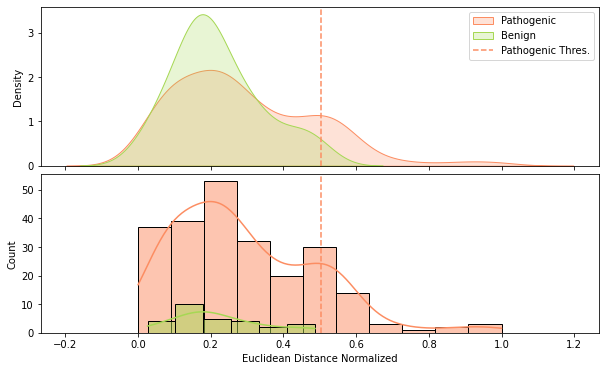

In [11]:
path_thres = 0.503

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["normalized_euclid_distance_normalized"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["normalized_euclid_distance_normalized"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
axes[0].legend()
axes[0].set_ylabel('Density')

sns.histplot(scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["normalized_euclid_distance_normalized"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["normalized_euclid_distance_normalized"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
axes[1].set_xlabel('Euclidean Distance Normalized')
axes[1].set_ylabel('Count')

plt.subplots_adjust(hspace=.05)
plt.show()

In [12]:
num_edge_filter = 1

benign_scores = scores_dedup.filter(pl.col("clinvar_clnsig_clean") == "2_Benign").filter(pl.col("num_edges") >= num_edge_filter)
# print(benign_scores.shape)

path_scores = scores_dedup.filter(pl.col("clinvar_clnsig_clean") == "1_Pathogenic").filter(pl.col("num_edges") >= num_edge_filter)
# print(path_scores.shape)

vus_scores = scores_dedup.filter(pl.col("clinvar_clnsig_clean") == "4_VUS").filter(pl.col("num_edges") >= num_edge_filter)
# print(vus_scores.shape)

conf_scores = scores_dedup.filter(pl.col("clinvar_clnsig_clean") == "3_Conflicting").filter(pl.col("num_edges") >= num_edge_filter)
# print(conf_scores.shape)

print(f"With this threshold, we capture {benign_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0]} benign alleles at ~5% error rate, which is {benign_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0] / benign_scores.shape[0] * 100:.2f}% of the benign alleles.")
print(f"With this threshold, we capture {path_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0]} pathogenic alleles at ~5% error rate, which is {path_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0] / path_scores.shape[0] * 100:.2f}% of the pathogenic alleles.")
print(f"With this threshold, we classify {vus_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0]} VUS and {conf_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0]} conflicting alleles as pathogenic at ~5% error rate, which is {vus_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0] / vus_scores.shape[0] * 100:.2f}% and {conf_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0] / conf_scores.shape[0] * 100:.2f}% of the VUS and conflicting alleles, respectively.")

With this threshold, we capture 0 benign alleles at ~5% error rate, which is 0.00% of the benign alleles.
With this threshold, we capture 44 pathogenic alleles at ~5% error rate, which is 18.80% of the pathogenic alleles.
With this threshold, we classify 9 VUS and 5 conflicting alleles as pathogenic at ~5% error rate, which is 9.89% and 6.67% of the VUS and conflicting alleles, respectively.


In [13]:
scores_dedup = scores_dedup.rename({"normalized_euclid_distance_normalized": "ppi_score_final_euclidean"}).with_columns(
    (pl.col("ppi_score_final_euclidean") > 0.503).alias("ppi_hit")
)
scores_dedup.write_csv(f"{sqy2h_outputs_dir}/6_variants_perturbation_scores_automated_annotated.csv")

In [14]:
scores_dedup

euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,normalized_euclid_distance,normalized_mahalanobis_distance,ppi_score_final_euclidean,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,orf_id,mut_id,symbol_right,aa_change_right,ensembl_gene_id_right,clinvar_clnsig_clean_right,gnomad_af_right,StarStatus_right,ppi_hit
f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,str,f64,f64,str,i64,i64,str,str,str,str,f64,f64,bool
6195.762408,6195.762408,0.740643,6195.762408,3.855687,3.855687,1.946988,1.946988,null,1,false,0.0,-6195.762408,-0.740643,null,2169.622247,0.259357,6195.762408,null,0.650942,"""PCCA""","""Met348Lys""","""1043T>A""","""ENSG00000175198""","""CEGS2""","""1_Pathogenic""",0.000003,2.0,"""PCCA_Met348Lys""",888,200363,"""PCCA""","""Met348Lys""","""ENSG00000175198""","""1_Pathogenic""",0.000003,2.0,true
5473.890499,5244.647308,0.748596,5244.647308,3.977664,3.977664,1.991921,1.991921,13.252449,4,false,0.0,-1415.580128,-0.251756,0.39299,1669.101986,0.251404,2736.94525,6.626225,0.28755,"""PRKAR1A""","""Arg335Pro""","""1004G>C""","""ENSG00000108946""","""CEGS2""","""1_Pathogenic""",null,null,"""PRKAR1A_Arg335Pro""",2455,200621,"""PRKAR1A""","""Arg335Pro""","""ENSG00000108946""","""1_Pathogenic""",null,null,false
1011.123445,-1011.123445,-0.152665,1011.123445,0.867555,0.867555,-0.204974,0.204974,null,1,false,0.0,1011.123445,0.152665,null,7634.263447,1.152665,1011.123445,null,0.106231,"""KCTD1""","""Gly62Asp""","""185G>A""","""ENSG00000134504""","""CEGS2""","""1_Pathogenic""",null,1.0,"""KCTD1_Gly62Asp""",14221,218283,"""KCTD1""","""Gly62Asp""","""ENSG00000134504""","""1_Pathogenic""",null,1.0,false
2742.168683,2742.168683,0.77832,2742.168683,4.511011,4.511011,2.173451,2.173451,null,1,false,0.0,-2742.168683,-0.77832,null,781.019624,0.22168,2742.168683,null,0.288099,"""AIPL1""","""Met79Thr""","""236T>C""","""ENSG00000129221""","""RC4""","""5_Others""",null,null,"""AIPL1_Met79Thr""",7167,12744,"""AIPL1""","""Met79Thr""","""ENSG00000129221""","""5_Others""",6.8407e-7,null,false
9028.451439,2760.240645,0.39926,2760.240645,1.664614,1.664614,0.735188,0.735188,null,15,false,0.0,834.023534,0.810715,2.802569,2523.666722,0.60074,2331.136138,null,0.244915,"""LITAF""","""Thr49Met""","""146C>T""","""ENSG00000189067""","""RC4""","""3_Conflicting""",null,1.0,"""LITAF_Thr49Met""",52920,2685,"""LITAF""","""Thr49Met""","""ENSG00000189067""","""3_Conflicting""",0.001281,1.0,false
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
5254.555658,4111.530892,0.833944,4111.530892,6.022076,6.022076,2.590261,2.590261,null,2,false,0.5,-3691.74137,-0.664619,0.239462,818.691519,0.166056,3715.531938,null,0.390363,"""KCNJ2""","""Val295Ala""","""884T>C""","""ENSG00000123700""","""Edgotyping3""","""4_VUS""",null,2.0,"""KCNJ2_Val295Ala""",100016069,2639,"""KCNJ2""","""Val295Ala""","""ENSG00000123700""","""4_VUS""",null,2.0,false
8313.960384,3848.001428,0.771227,3848.001428,4.371149,4.371149,2.128013,2.128013,null,15,false,0.0,-620.828675,0.352359,1.897952,1141.451004,0.228773,2146.655341,null,0.225533,"""LITAF""","""Pro135Thr""","""403C>A""","""ENSG00000189067""","""Edgotyping3""","""1_Pathogenic""",null,1.0,"""LITAF_Pro135Thr""",52920,2669,"""LITAF""","""Pro135Thr""","""ENSG00000189067""","""1_Pathogenic""",null,1.0,false
5159.908705,-5159.908705,-1.587944,5159.908705,0.386407,0.386407,-1.371806,1.371806,null,1,false,0.0,5159.908705,1.587944,null,8409.336233,2.587944,5159.908705,null,0.542112,"""VHL""","""Ser65Trp""","""194C>G""","""ENSG00000134086""","""RC4""","""1_Pathogenic""",6.8942e-7,3.0,"""VHL_Ser65Trp""",13320

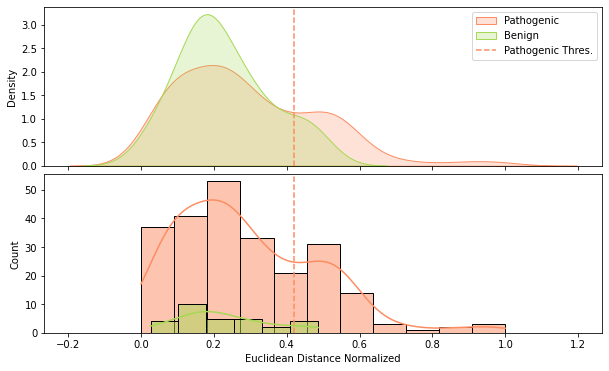

In [24]:

path_thres = 0.42

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=scores.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["normalized_euclid_distance_normalized"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=scores.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["normalized_euclid_distance_normalized"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
axes[0].legend()

sns.histplot(scores.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["normalized_euclid_distance_normalized"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(scores.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["normalized_euclid_distance_normalized"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
axes[1].set_xlabel('Euclidean Distance Normalized')
plt.subplots_adjust(hspace=.05)
plt.show()

In [25]:
manual_thresh = 0.42

num_edge_filter = 1

benign_scores = scores_dedup.filter(pl.col("clinvar_clnsig_clean") == "2_Benign").filter(pl.col("num_edges") >= num_edge_filter)
# print(benign_scores.shape)

path_scores = scores_dedup.filter(pl.col("clinvar_clnsig_clean") == "1_Pathogenic").filter(pl.col("num_edges") >= num_edge_filter)
# print(path_scores.shape)

vus_scores = scores_dedup.filter(pl.col("clinvar_clnsig_clean") == "4_VUS").filter(pl.col("num_edges") >= num_edge_filter)
# print(vus_scores.shape)

conf_scores = scores_dedup.filter(pl.col("clinvar_clnsig_clean") == "3_Conflicting").filter(pl.col("num_edges") >= num_edge_filter)
# print(conf_scores.shape)

print(f"With this threshold, we capture {benign_scores.filter(pl.col('ppi_score_final_euclidean') > manual_thresh).shape[0]} benign alleles at ~5% error rate, which is {benign_scores.filter(pl.col('ppi_score_final_euclidean') > manual_thresh).shape[0] / benign_scores.shape[0] * 100:.2f}% of the benign alleles.")
print(f"With this threshold, we capture {path_scores.filter(pl.col('ppi_score_final_euclidean') > manual_thresh).shape[0]} pathogenic alleles at ~5% error rate, which is {path_scores.filter(pl.col('ppi_score_final_euclidean') > manual_thresh).shape[0] / path_scores.shape[0] * 100:.2f}% of the pathogenic alleles.")
print(f"With this threshold, we classify {vus_scores.filter(pl.col('ppi_score_final_euclidean') > manual_thresh).shape[0]} VUS and {conf_scores.filter(pl.col('ppi_score_final_euclidean') > manual_thresh).shape[0]} conflicting alleles as pathogenic at ~5% error rate, which is {vus_scores.filter(pl.col('ppi_score_final_euclidean') > manual_thresh).shape[0] / vus_scores.shape[0] * 100:.2f}% and {conf_scores.filter(pl.col('ppi_score_final_euclidean') > manual_thresh).shape[0] / conf_scores.shape[0] * 100:.2f}% of the VUS and conflicting alleles, respectively.")

With this threshold, we capture 3 benign alleles at ~5% error rate, which is 10.71% of the benign alleles.
With this threshold, we capture 62 pathogenic alleles at ~5% error rate, which is 26.50% of the pathogenic alleles.
With this threshold, we classify 19 VUS and 12 conflicting alleles as pathogenic at ~5% error rate, which is 20.88% and 16.00% of the VUS and conflicting alleles, respectively.


# exploring scores

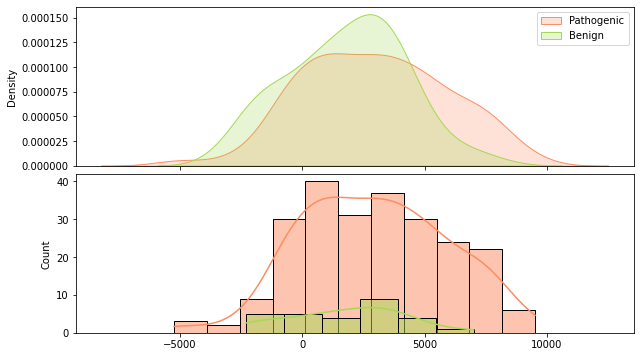

In [15]:
path_thres = 0.503

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["max_perturbation"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["max_perturbation"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
# axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
axes[0].legend()

sns.histplot(scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["max_perturbation"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["max_perturbation"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
# axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
plt.subplots_adjust(hspace=.05)
plt.show()

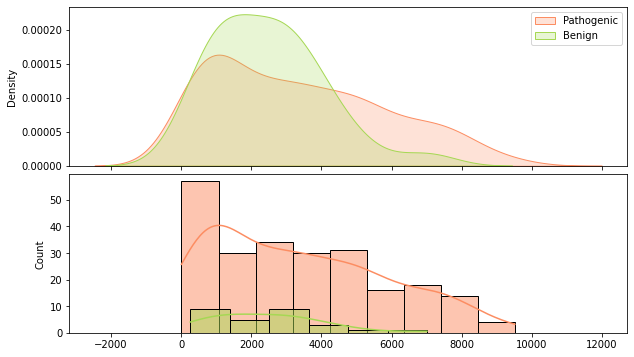

In [16]:
path_thres = 0.503

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["max_perturbation_abs"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["max_perturbation_abs"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
# axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
axes[0].legend()

sns.histplot(scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["max_perturbation_abs"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["max_perturbation_abs"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
# axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
plt.subplots_adjust(hspace=.05)
plt.show()

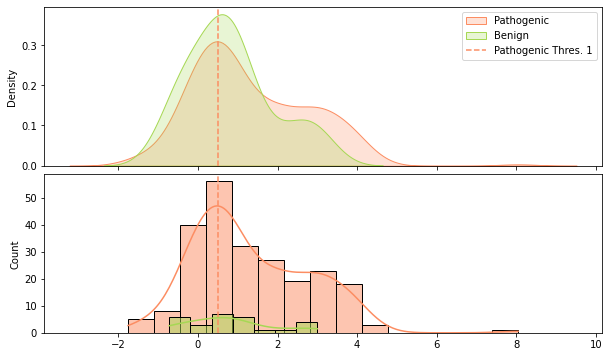

In [17]:

path_thres = 0.503

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["max_log2_fold_change"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["max_log2_fold_change"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
axes[0].legend()

sns.histplot(scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["max_log2_fold_change"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["max_log2_fold_change"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
plt.subplots_adjust(hspace=.05)
plt.show()

# summarizing plots

In [18]:
scores_dedup = scores_dedup.with_columns(
    (pl.col("ppi_score_final_euclidean") > 0.42).alias("ppi_hit_manual"),
)

In [19]:
scores_dedup

euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,normalized_euclid_distance,normalized_mahalanobis_distance,ppi_score_final_euclidean,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,orf_id,mut_id,symbol_right,aa_change_right,ensembl_gene_id_right,clinvar_clnsig_clean_right,gnomad_af_right,StarStatus_right,ppi_hit,ppi_hit_manual
f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,str,f64,f64,str,i64,i64,str,str,str,str,f64,f64,bool,bool
6195.762408,6195.762408,0.740643,6195.762408,3.855687,3.855687,1.946988,1.946988,null,1,false,0.0,-6195.762408,-0.740643,null,2169.622247,0.259357,6195.762408,null,0.650942,"""PCCA""","""Met348Lys""","""1043T>A""","""ENSG00000175198""","""CEGS2""","""1_Pathogenic""",0.000003,2.0,"""PCCA_Met348Lys""",888,200363,"""PCCA""","""Met348Lys""","""ENSG00000175198""","""1_Pathogenic""",0.000003,2.0,true,true
5473.890499,5244.647308,0.748596,5244.647308,3.977664,3.977664,1.991921,1.991921,13.252449,4,false,0.0,-1415.580128,-0.251756,0.39299,1669.101986,0.251404,2736.94525,6.626225,0.28755,"""PRKAR1A""","""Arg335Pro""","""1004G>C""","""ENSG00000108946""","""CEGS2""","""1_Pathogenic""",null,null,"""PRKAR1A_Arg335Pro""",2455,200621,"""PRKAR1A""","""Arg335Pro""","""ENSG00000108946""","""1_Pathogenic""",null,null,false,false
1011.123445,-1011.123445,-0.152665,1011.123445,0.867555,0.867555,-0.204974,0.204974,null,1,false,0.0,1011.123445,0.152665,null,7634.263447,1.152665,1011.123445,null,0.106231,"""KCTD1""","""Gly62Asp""","""185G>A""","""ENSG00000134504""","""CEGS2""","""1_Pathogenic""",null,1.0,"""KCTD1_Gly62Asp""",14221,218283,"""KCTD1""","""Gly62Asp""","""ENSG00000134504""","""1_Pathogenic""",null,1.0,false,false
2742.168683,2742.168683,0.77832,2742.168683,4.511011,4.511011,2.173451,2.173451,null,1,false,0.0,-2742.168683,-0.77832,null,781.019624,0.22168,2742.168683,null,0.288099,"""AIPL1""","""Met79Thr""","""236T>C""","""ENSG00000129221""","""RC4""","""5_Others""",null,null,"""AIPL1_Met79Thr""",7167,12744,"""AIPL1""","""Met79Thr""","""ENSG00000129221""","""5_Others""",6.8407e-7,null,false,false
9028.451439,2760.240645,0.39926,2760.240645,1.664614,1.664614,0.735188,0.735188,null,15,false,0.0,834.023534,0.810715,2.802569,2523.666722,0.60074,2331.136138,null,0.244915,"""LITAF""","""Thr49Met""","""146C>T""","""ENSG00000189067""","""RC4""","""3_Conflicting""",null,1.0,"""LITAF_Thr49Met""",52920,2685,"""LITAF""","""Thr49Met""","""ENSG00000189067""","""3_Conflicting""",0.001281,1.0,false,false
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
5254.555658,4111.530892,0.833944,4111.530892,6.022076,6.022076,2.590261,2.590261,null,2,false,0.5,-3691.74137,-0.664619,0.239462,818.691519,0.166056,3715.531938,null,0.390363,"""KCNJ2""","""Val295Ala""","""884T>C""","""ENSG00000123700""","""Edgotyping3""","""4_VUS""",null,2.0,"""KCNJ2_Val295Ala""",100016069,2639,"""KCNJ2""","""Val295Ala""","""ENSG00000123700""","""4_VUS""",null,2.0,false,false
8313.960384,3848.001428,0.771227,3848.001428,4.371149,4.371149,2.128013,2.128013,null,15,false,0.0,-620.828675,0.352359,1.897952,1141.451004,0.228773,2146.655341,null,0.225533,"""LITAF""","""Pro135Thr""","""403C>A""","""ENSG00000189067""","""Edgotyping3""","""1_Pathogenic""",null,1.0,"""LITAF_Pro135Thr""",52920,2669,"""LITAF""","""Pro135Thr""","""ENSG00000189067""","""1_Pathogenic""",null,1.0,false,false
5159.908705,-5159.908705,-1.587944,5159.908705,0.386407,0.386407,-1.371806,1.371806,null,1,false,0.0,5159.908705,1.587944,null,8409.336233,2.587944,5159.908705,null,0.542112,"""VHL""","""Ser65Trp""","""194C>G""","""ENSG00000134086""","""R

clinvar_clnsig_clean,total_counts,hit_counts,hit_perc
str,u32,u32,f64
"""1_Pathogenic""",234,44,18.803419
"""2_Benign""",28,0,0.0
"""3_Conflicting""",75,5,6.666667
"""4_VUS""",91,9,9.89011
"""5_Others""",42,1,2.380952


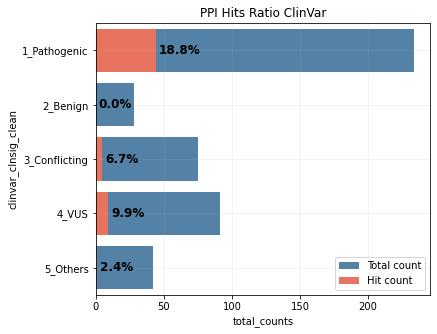

In [20]:
# Add gene_variant column to match the function expectation
scores_dedup_with_gene_variant = scores_dedup.with_columns(
    pl.col("allele_0").alias("gene_variant")
)

scores_dedup_with_gene_variant = scores_dedup_with_gene_variant.filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","3_Conflicting","4_VUS","5_Others","6_No_ClinVar"]) #pl.col("Gene")!="BRCA1" #
)

plot_assay_hit_by_category(scores_dedup_with_gene_variant, "ppi_hit", "clinvar_clnsig_clean", f"PPI Hits Ratio ClinVar")

clinvar_clnsig_clean,total_counts,hit_counts,hit_perc
str,u32,u32,f64
"""1_Pathogenic""",234,62,26.495726
"""2_Benign""",28,3,10.714286
"""3_Conflicting""",75,12,16.0
"""4_VUS""",91,19,20.879121
"""5_Others""",42,2,4.761905


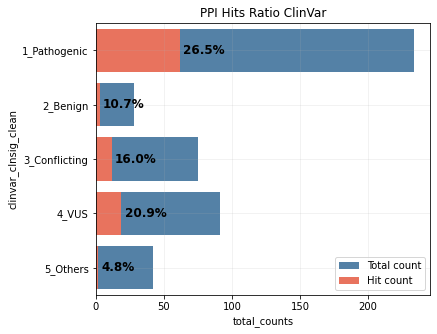

In [21]:
# Add gene_variant column to match the function expectation
scores_dedup_with_gene_variant = scores_dedup.with_columns(
    pl.col("allele_0").alias("gene_variant")
)

scores_dedup_with_gene_variant = scores_dedup_with_gene_variant.filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","3_Conflicting","4_VUS","5_Others","6_No_ClinVar"]) #pl.col("Gene")!="BRCA1" #
)

plot_assay_hit_by_category(scores_dedup_with_gene_variant, "ppi_hit_manual", "clinvar_clnsig_clean", f"PPI Hits Ratio ClinVar")

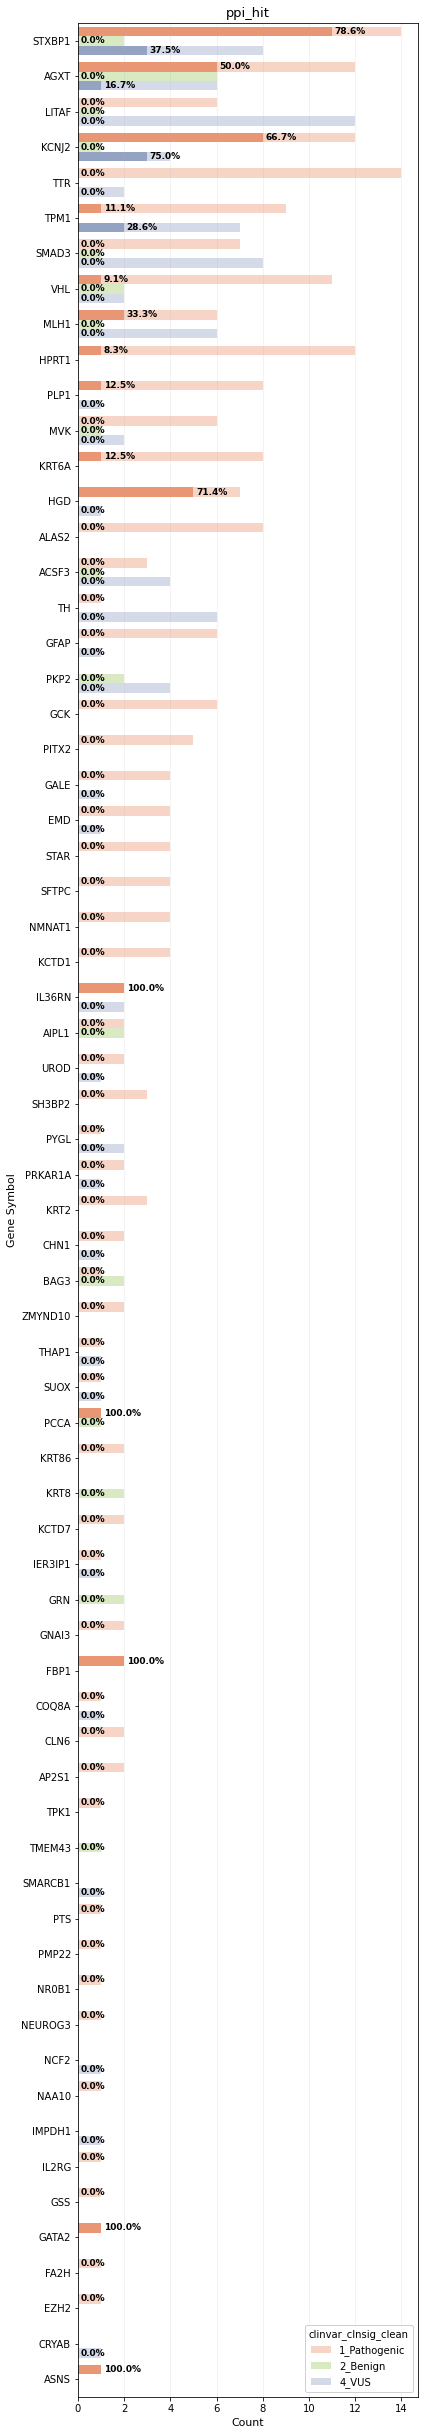

,symbol,clinvar_clnsig_clean,total_counts,hit_counts,hit_perc,total_counts_all
0,STXBP1,1_Pathogenic,14,11,78.571429,24
1,STXBP1,2_Benign,2,0,0.000000,24
2,STXBP1,4_VUS,8,3,37.500000,24
3,AGXT,1_Pathogenic,12,6,50.000000,24
4,AGXT,2_Benign,6,0,0.000000,24
...,...,...,...,...,...,...
101,GATA2,1_Pathogenic,1,1,100.000000,1
102,FA2H,1_Pathogenic,1,0,0.000000,1
103,EZH2,1_Pathogenic,1,0,0.000000,1
104,CRYAB,4_VUS,1,0,0.000000,1


In [22]:
plot_gene_level_summary(
    assay_df=scores_dedup_with_gene_variant.filter(
        pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","4_VUS"])
    ),
    assay="ppi_hit",
    palette=palette_dict["clinvar_clnsig_clean"]
)

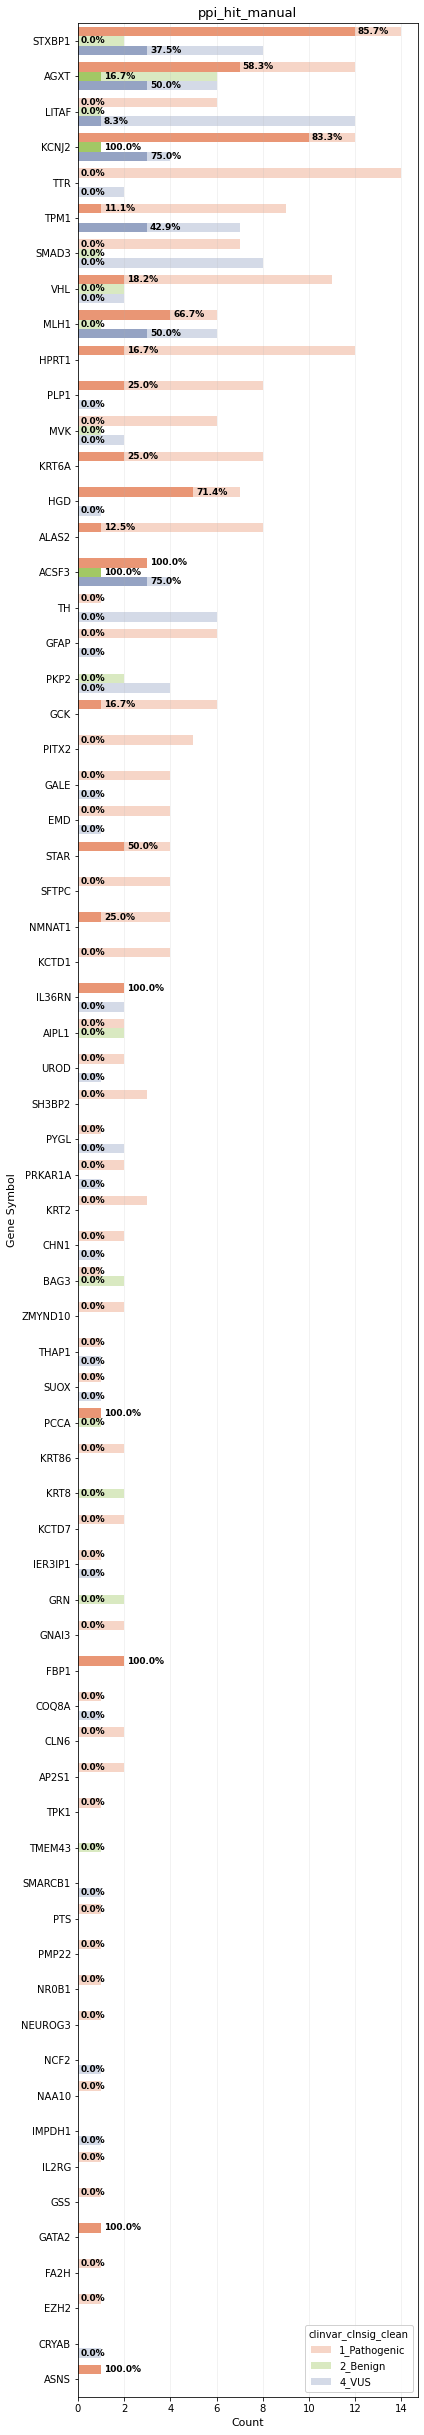

,symbol,clinvar_clnsig_clean,total_counts,hit_counts,hit_perc,total_counts_all
0,STXBP1,1_Pathogenic,14,12,85.714286,24
1,STXBP1,2_Benign,2,0,0.000000,24
2,STXBP1,4_VUS,8,3,37.500000,24
3,AGXT,1_Pathogenic,12,7,58.333333,24
4,AGXT,2_Benign,6,1,16.666667,24
...,...,...,...,...,...,...
101,GATA2,1_Pathogenic,1,1,100.000000,1
102,FA2H,1_Pathogenic,1,0,0.000000,1
103,EZH2,1_Pathogenic,1,0,0.000000,1
104,CRYAB,4_VUS,1,0,0.000000,1


In [26]:
plot_gene_level_summary(
    assay_df=scores_dedup_with_gene_variant.filter(
        pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","4_VUS"])
    ),
    assay="ppi_hit_manual",
    palette=palette_dict["clinvar_clnsig_clean"]
)